# 01 Data exploration and cleaning

**Question:** Is the raw catalog suitable for semantic search? Inspect missing values, identifiers, and description lengths before modeling. Use the project virtual environment as this notebook's kernel. First run `python -m scripts.download_data` in the project root.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "book_recommender").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from book_recommender.config import RAW, CLEAN, CLASSIFIED, ENRICHED, REPORTS


## Inspect the raw data
ISBNs are identifiers, not numbers. Preserve leading zeros by reading them as strings. The dataset includes several metadata fields that are useful for displaying and auditing recommendations.

In [2]:
raw = pd.read_csv(RAW, dtype={"isbn13": str, "isbn10": str})
print(raw.shape)
raw.head(3)

(6810, 12)


,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0


In [3]:
raw.isna().sum().sort_values(ascending=False).to_frame("missing_rows")

,missing_rows
subtitle,4429
thumbnail,329
description,262
categories,99
authors,72
average_rating,43
ratings_count,43
num_pages,43
published_year,6
title,0


## Apply explicit cleaning rules
Keep descriptions of at least 20 words, valid 13-digit IDs, and nonempty titles. Deduplicate by ISBN; do not remove records merely because covers or authors are missing. Twenty words is a heuristic worth testing, not an objective definition of quality.

In [4]:
from book_recommender.data_exploration import run
books, report = run()
report

{'input_rows': 6810,
 'missing_values': {'isbn13': 0,
  'isbn10': 0,
  'title': 0,
  'subtitle': 4429,
  'authors': 72,
  'categories': 99,
  'thumbnail': 329,
  'description': 262,
  'published_year': 6,
  'average_rating': 43,
  'num_pages': 43,
  'ratings_count': 43},
 'minimum_description_words': 20,
 'invalid_identifier_or_title': 0,
 'short_or_missing_description': 1081,
 'duplicate_isbns': 0,
 'output_rows': 5729}

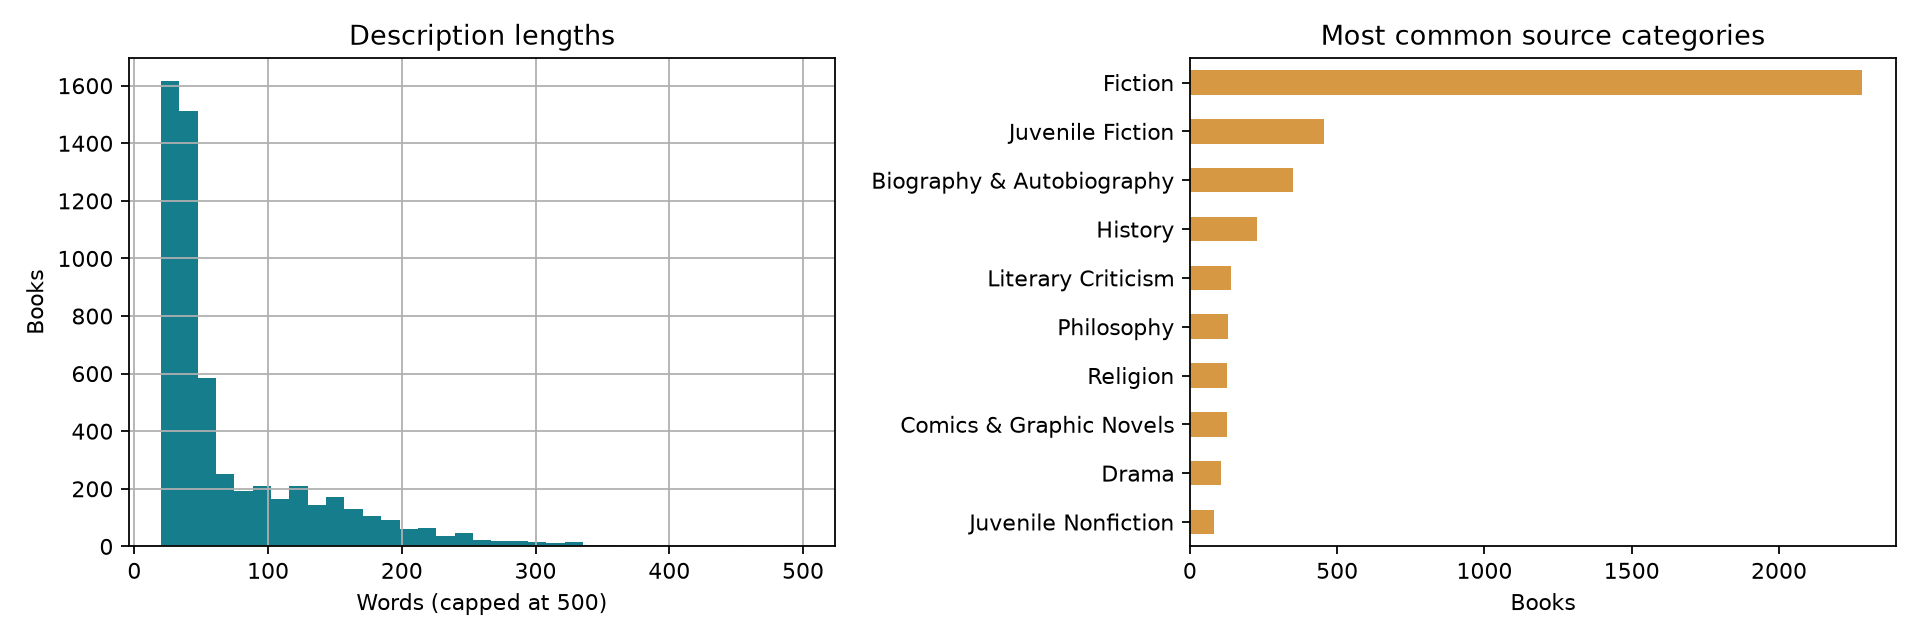

In [5]:
from IPython.display import Image, display
display(Image(filename=str(REPORTS / "data_exploration.png")))

## Check the result
Each book must map to one unique vector ID. Different editions can still share descriptions, so unique ISBNs do not guarantee unique semantic content.

In [6]:
assert books.book_id.is_unique
assert books.description_words.min() >= 20
books[["book_id", "title", "description_words"]].head()

,book_id,title,description_words
0,9780002005883,Gilead,199
1,9780002261982,Spider's Web,205
2,9780006178736,Rage of angels,57
3,9780006280897,The Four Loves,45
4,9780006280934,The Problem of Pain,75


## Think about the tradeoff
Which useful short blurbs did cleaning remove? Compare thresholds of 10, 20, and 30 using `clean_books(raw, min_words=...)` before deciding. The next notebook predicts a broad fiction category.